In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/california-housing-prices")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Path to dataset files: /kaggle/input/california-housing-prices


In [ ]:
import os

# Locate the CSV file in the downloaded directory
csv_file = None
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith('.csv'):
            csv_file = os.path.join(root, file)
            break

if csv_file:
    print(f"Loading dataset from: {csv_file}")
    df = pd.read_csv(csv_file)
else:
    raise FileNotFoundError("No CSV file found in the downloaded dataset directory.")

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Loading dataset from: /kaggle/input/california-housing-prices/housing.csv

Statistical summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN



Data types:


,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object



Missing values:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0



Duplicate rows: 0


In [ ]:
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]
target = "median_house_value"

# Check that the selected columns exist in the uploaded file
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}. "
        "Please check that you uploaded the California housing.csv dataset."
    )

X_raw = df[features].copy()
y = pd.to_numeric(df[target], errors="coerce")

# Ensure feature columns are numeric
X_raw = X_raw.apply(pd.to_numeric, errors="coerce")

# Remove rows with missing target values; features will be imputed later
valid_target = y.notna()
X_raw = X_raw.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].reset_index(drop=True)

print("Input features:", features)
print("Target:", target)
print("X shape:", X_raw.shape)
print("y shape:", y.shape)

Input features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Target: median_house_value
X shape: (20640, 8)
y shape: (20640,)


In [ ]:
print("Missing values in input features:")
display(X_raw.isnull().sum())

print("Infinite values in input features:",
      np.isinf(X_raw.to_numpy(dtype=float)).sum())

print("Duplicate rows:", X_raw.duplicated().sum())
print("Missing target values:", y.isnull().sum())

# Replace infinite feature values with missing values so the imputer can handle them
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

print("\\nData inspection completed.")

Missing values in input features:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0


Infinite values in input features: 0
Duplicate rows: 0
Missing target values: 0
\nData inspection completed.


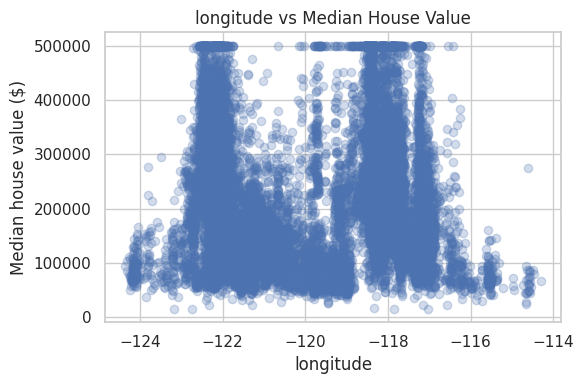

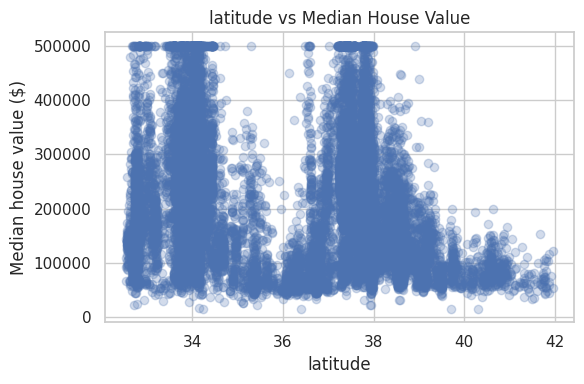

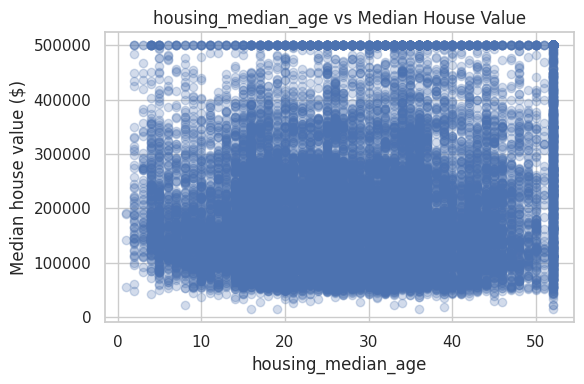

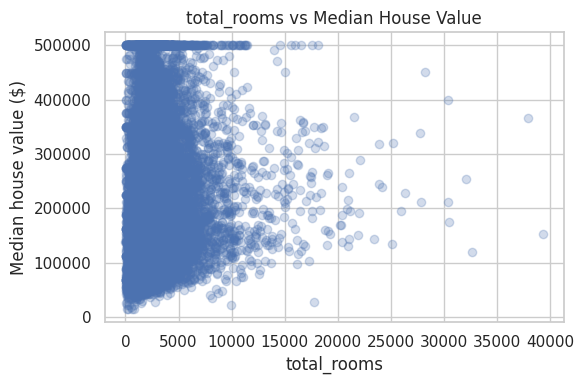

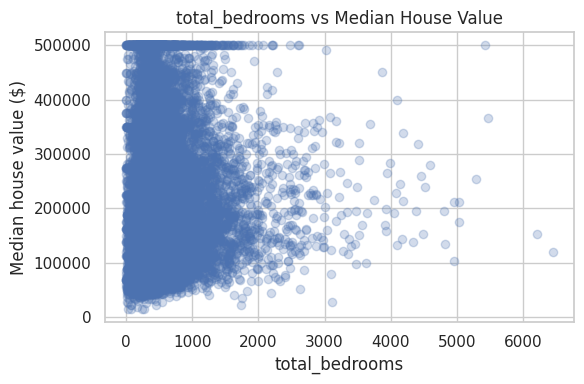

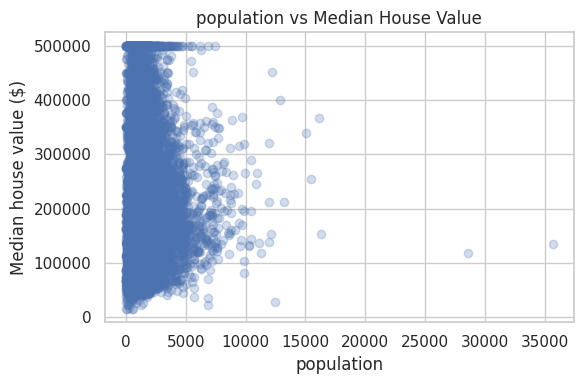

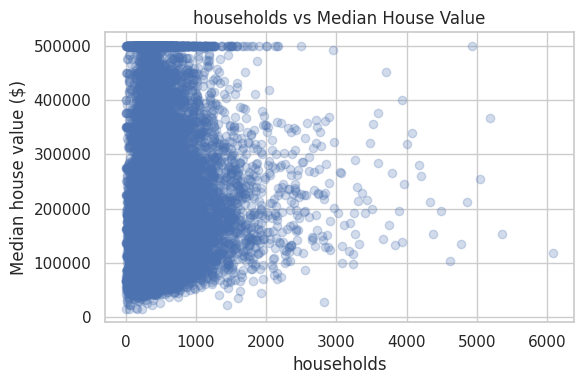

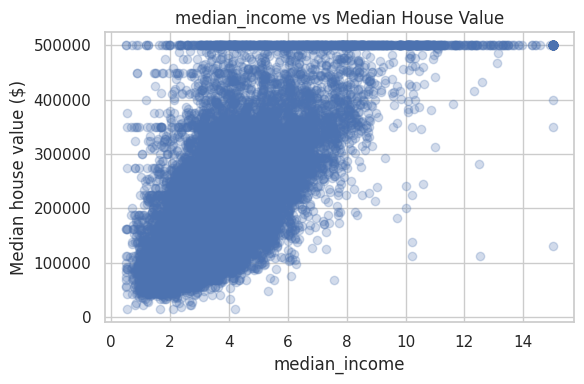

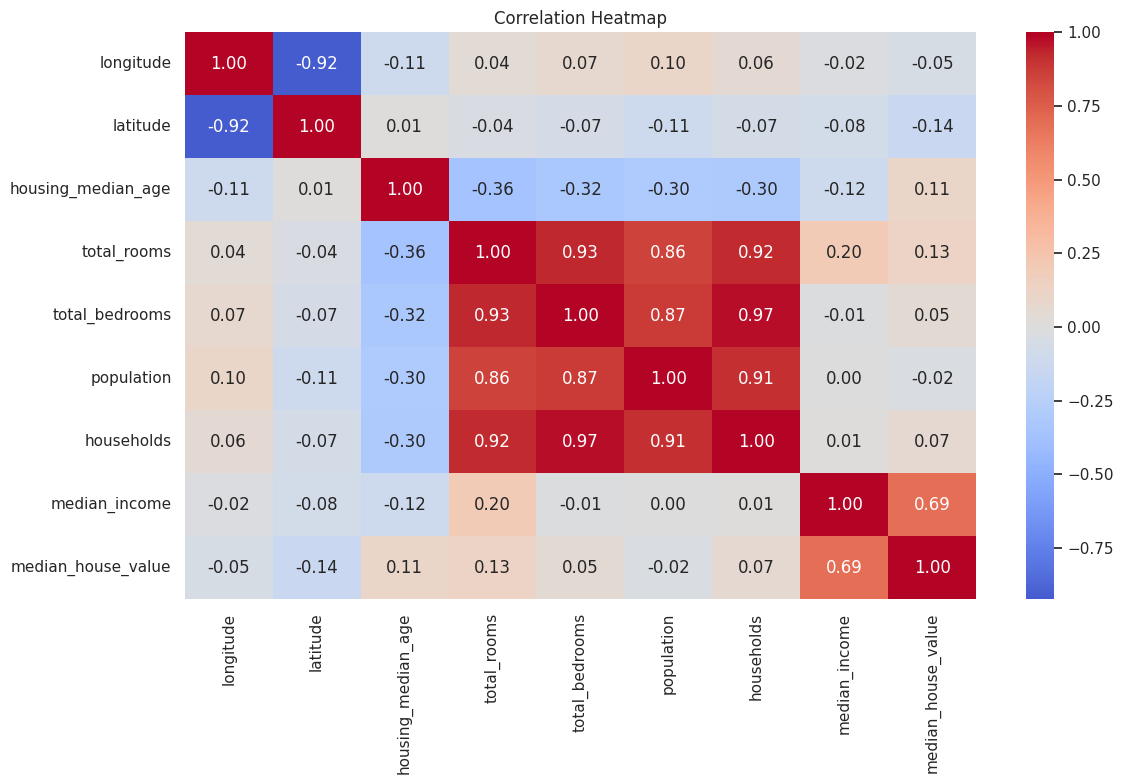

Correlation of each feature with the target:


,Correlation with target
median_income,0.688075
latitude,-0.144160
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049457
longitude,-0.045967
population,-0.024650


In [ ]:
X_eda = X_raw.fillna(X_raw.median(numeric_only=True))
eda_data = pd.concat([X_eda, y.rename(target)], axis=1)

# Scatter plots: each input feature against the target
for feature in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(eda_data[feature], y, alpha=0.25)
    plt.xlabel(feature)
    plt.ylabel("Median house value ($)")
    plt.title(f"{feature} vs Median House Value")
    plt.tight_layout()
    plt.show()

# Correlation matrix and heatmap
correlation = eda_data.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation of each feature with the target:")
display(
    correlation[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .to_frame("Correlation with target")
)

In [ ]:
manual_columns = ["median_income", "housing_median_age", "median_house_value"]
manual_data = df[manual_columns].copy()

for col in manual_columns:
    manual_data[col] = pd.to_numeric(manual_data[col], errors="coerce")

manual_data = manual_data.replace([np.inf, -np.inf], np.nan).dropna().head(5)

if len(manual_data) < 3:
    raise ValueError("At least 3 complete observations are needed for manual calculation.")

display(manual_data)

X_manual = np.column_stack([
    np.ones(len(manual_data)),
    manual_data["median_income"].to_numpy(),
    manual_data["housing_median_age"].to_numpy()
])
y_manual = manual_data["median_house_value"].to_numpy()

print("Design matrix X:")
print(X_manual)

print("\\nTarget vector y:")
print(y_manual)

,median_income,housing_median_age,median_house_value
0,8.3252,41.0,452600.0
1,8.3014,21.0,358500.0
2,7.2574,52.0,352100.0
3,5.6431,52.0,341300.0
4,3.8462,52.0,342200.0


Design matrix X:
[[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]]
\nTarget vector y:
[452600. 358500. 352100. 341300. 342200.]


In [ ]:
XT = X_manual.T
XTX = XT @ X_manual
XTy = XT @ y_manual

print("X transpose:")
print(XT)

print("\\nX transpose multiplied by X (XTX):")
print(XTX)

print("\\nX transpose multiplied by y (XTy):")
print(XTy)

X transpose:
[[ 1.      1.      1.      1.      1.    ]
 [ 8.3252  8.3014  7.2574  5.6431  3.8462]
 [41.     21.     52.     52.     52.    ]]
\nX transpose multiplied by X (XTX):
[[5.00000000e+00 3.33733000e+01 2.18000000e+02]
 [3.33733000e+01 2.37529884e+02 1.38649100e+03]
 [2.18000000e+02 1.38649100e+03 1.02340000e+04]]
\nX transpose multiplied by y (XTy):
[ 1846700.   12541527.63 79936300.  ]


In [ ]:
coefficients_manual = np.linalg.solve(XTX, XTy)

b0, b1, b2 = coefficients_manual

print(f"Intercept (b0): {b0:.4f}")
print(f"Median income coefficient (b1): {b1:.4f}")
print(f"Housing age coefficient (b2): {b2:.4f}")
print(
    f"Fitted equation: y = {b0:.2f} + "
    f"({b1:.2f} × median_income) + "
    f"({b2:.2f} × housing_median_age)"
)

Intercept (b0): 195717.6709
Median income coefficient (b1): 19330.1015
Housing age coefficient (b2): 1022.9466
Fitted equation: y = 195717.67 + (19330.10 × median_income) + (1022.95 × housing_median_age)


In [ ]:
x1 = X_manual[0, 1]
x2 = X_manual[0, 2]
actual_manual = y_manual[0]

predicted_manual = b0 + b1 * x1 + b2 * x2
residual_manual = actual_manual - predicted_manual

print("Actual value:", actual_manual)
print("Predicted value:", predicted_manual)
print("Residual (actual - predicted):", residual_manual)

Actual value: 452600.0
Predicted value: 398585.44448374654
Residual (actual - predicted): 54014.55551625346


In [ ]:
# Scikit-learn on the same five rows
manual_library_model = LinearRegression()
manual_library_model.fit(
    manual_data[["median_income", "housing_median_age"]],
    y_manual
)

print("Manual coefficients:", coefficients_manual)
print("Library intercept:", manual_library_model.intercept_)
print("Library coefficients:", manual_library_model.coef_)

Manual coefficients: [195717.670917    19330.10151752   1022.94664422]
Library intercept: 195717.67091700184
Library coefficients: [19330.10151752  1022.94664422]


In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train_raw))
print("Testing records:", len(X_test_raw))

# Impute missing feature values using training medians only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=features,
    index=X_train_raw.index
)
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=features,
    index=X_test_raw.index
)

print("Missing values after imputation (train):", X_train.isnull().sum().sum())
print("Missing values after imputation (test):", X_test.isnull().sum().sum())

Training records: 16512
Testing records: 4128
Missing values after imputation (train): 0
Missing values after imputation (test): 0


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed.
Scaled training shape: (16512, 8)
Scaled testing shape: (4128, 8)


In [ ]:
train_for_corr = X_train.copy()
train_for_corr[target] = y_train

train_corr = train_for_corr.corr(numeric_only=True)
strongest_feature = (
    train_corr[target]
    .drop(target)
    .abs()
    .idxmax()
)

print("Strongest feature by absolute training correlation:", strongest_feature)

single_model = LinearRegression()
single_model.fit(X_train[[strongest_feature]], y_train)

single_pred = single_model.predict(X_test[[strongest_feature]])

print("Single-feature model intercept:", single_model.intercept_)
print("Single-feature coefficient:", single_model.coef_[0])
print("Single-feature test R2:", r2_score(y_test, single_pred))

Strongest feature by absolute training correlation: median_income
Single-feature model intercept: 44459.72916907875
Single-feature coefficient: 41933.84939381272
Single-feature test R2: 0.45885918903846656


In [ ]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_pred = multiple_model.predict(X_test)

print("Multiple Linear Regression model trained.")
print("Intercept:", multiple_model.intercept_)

coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": multiple_model.coef_
})
display(coefficient_table)

equation = f"y = {multiple_model.intercept_:.2f}"
for feature, coef in zip(features, multiple_model.coef_):
    equation += f" + ({coef:.4f} × {feature})"

print("\\nFitted equation:")
print(equation)

Multiple Linear Regression model trained.
Intercept: -3578224.2348185843


,Feature,Coefficient
0,longitude,-42632.391717
1,latitude,-42450.071864
2,housing_median_age,1182.809649
3,total_rooms,-8.187977
4,total_bedrooms,116.260128
5,population,-38.492213
6,households,46.342572
7,median_income,40538.404387


\nFitted equation:
y = -3578224.23 + (-42632.3917 × longitude) + (-42450.0719 × latitude) + (1182.8096 × housing_median_age) + (-8.1880 × total_rooms) + (116.2601 × total_bedrooms) + (-38.4922 × population) + (46.3426 × households) + (40538.4044 × median_income)


In [ ]:
# Actual versus predicted values on the test set
comparison = pd.DataFrame({
    "Actual House Value": y_test.to_numpy(),
    "Predicted House Value": multiple_pred
})

display(comparison.head(10))

,Actual House Value,Predicted House Value
0,47700.0,63969.111594
1,45800.0,154577.114574
2,500001.0,253305.714543
3,218600.0,263740.266791
4,278000.0,267115.879866
5,158700.0,155636.014721
6,198200.0,287291.174456
7,157500.0,223893.301808
8,340000.0,257277.547438
9,446600.0,404505.886368


In [ ]:
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

standardized_coefficients = pd.DataFrame({
    "Feature": features,
    "Original Coefficient": multiple_model.coef_,
    "Standardized Coefficient": scaled_model.coef_
})

display(standardized_coefficients.sort_values(
    "Standardized Coefficient",
    key=lambda values: values.abs(),
    ascending=False
))

,Feature,Original Coefficient,Standardized Coefficient
1,latitude,-42450.071864,-90698.848803
0,longitude,-42632.391717,-85503.218153
7,median_income,40538.404387,77194.699466
4,total_bedrooms,116.260128,48712.343341
5,population,-38.492213,-43766.491159
3,total_rooms,-8.187977,-17805.418501
6,households,46.342572,17654.500659
2,housing_median_age,1182.809649,14905.906448


In [ ]:
def evaluate_model(y_actual, y_predicted, number_of_features):
    mae = mean_absolute_error(y_actual, y_predicted)
    mse = mean_squared_error(y_actual, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_predicted)

    n = len(y_actual)
    p = number_of_features
    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted R2": adjusted_r2
    }

single_results = evaluate_model(y_test, single_pred, 1)
multiple_results = evaluate_model(y_test, multiple_pred, len(features))

results = pd.DataFrame(
    [single_results, multiple_results],
    index=["Single-feature model", "Multiple-feature model"]
)

display(results)

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature model,62990.865301,7.091158e+09,84209.012414,0.458859,0.458728
Multiple-feature model,51810.089335,5.059656e+09,71131.259184,0.613887,0.613137


In [ ]:
print("Single-feature test metrics:")
for metric, value in single_results.items():
    print(f"{metric}: {value:,.4f}")

print("\\nMultiple-feature test metrics:")
for metric, value in multiple_results.items():
    print(f"{metric}: {value:,.4f}")

if multiple_results["RMSE"] < single_results["RMSE"]:
    print("\\nThe multiple-feature model has lower test RMSE.")
else:
    print("\\nThe single-feature model has equal or lower test RMSE.")

if multiple_results["Adjusted R2"] > single_results["Adjusted R2"]:
    print("The multiple-feature model also has higher adjusted R2.")
else:
    print("The multiple-feature model does not have higher adjusted R2.")

Single-feature test metrics:
MAE: 62,990.8653
MSE: 7,091,157,771.7655
RMSE: 84,209.0124
R2: 0.4589
Adjusted R2: 0.4587
\nMultiple-feature test metrics:
MAE: 51,810.0893
MSE: 5,059,656,033.1261
RMSE: 71,131.2592
R2: 0.6139
Adjusted R2: 0.6131
\nThe multiple-feature model has lower test RMSE.
The multiple-feature model also has higher adjusted R2.


In [ ]:
residuals = y_test.to_numpy() - multiple_pred

residual_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": multiple_pred,
    "Residual": residuals
})

display(residual_df.head(10))

,Actual,Predicted,Residual
0,47700.0,63969.111594,-16269.111594
1,45800.0,154577.114574,-108777.114574
2,500001.0,253305.714543,246695.285457
3,218600.0,263740.266791,-45140.266791
4,278000.0,267115.879866,10884.120134
5,158700.0,155636.014721,3063.985279
6,198200.0,287291.174456,-89091.174456
7,157500.0,223893.301808,-66393.301808
8,340000.0,257277.547438,82722.452562
9,446600.0,404505.886368,42094.113632


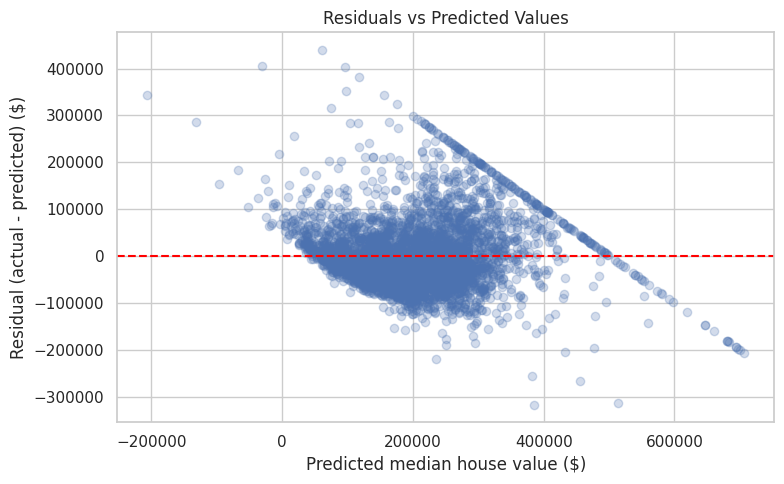

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(multiple_pred, residuals, alpha=0.25)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted median house value ($)")
plt.ylabel("Residual (actual - predicted) ($)")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

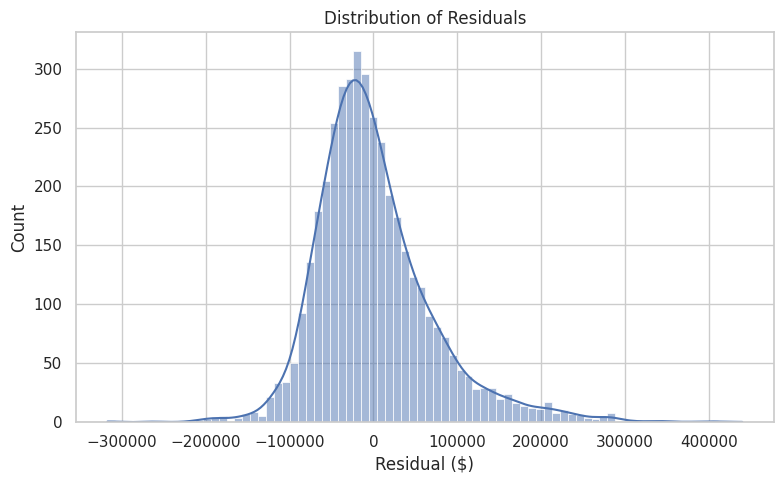

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual ($)")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.show()

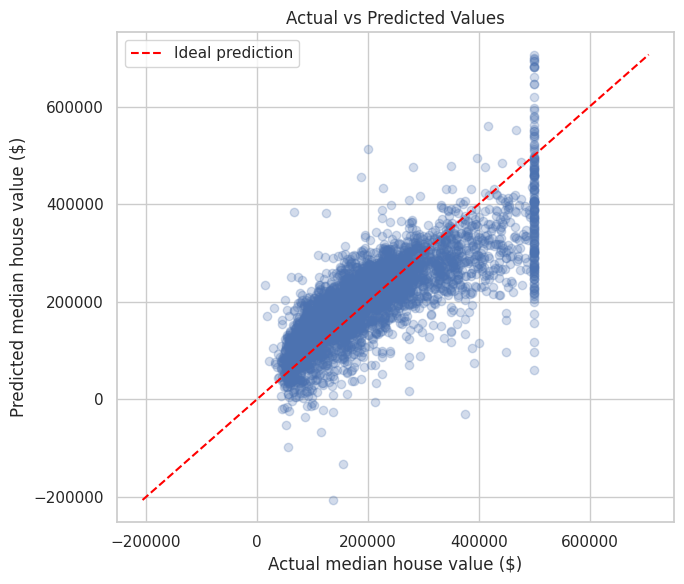

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, multiple_pred, alpha=0.25)

lower = min(y_test.min(), multiple_pred.min())
upper = max(y_test.max(), multiple_pred.max())

plt.plot([lower, upper], [lower, upper], color="red", linestyle="--",
         label="Ideal prediction")
plt.xlabel("Actual median house value ($)")
plt.ylabel("Predicted median house value ($)")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
vif_data = pd.DataFrame({
    "Feature": features,
    "VIF": [
        variance_inflation_factor(X_train_scaled, i)
        for i in range(len(features))
    ]
})

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
4,total_bedrooms,36.307087
6,households,35.824564
3,total_rooms,12.821807
1,latitude,8.798267
0,longitude,8.681823
5,population,6.345431
7,median_income,1.740998
2,housing_median_age,1.257629


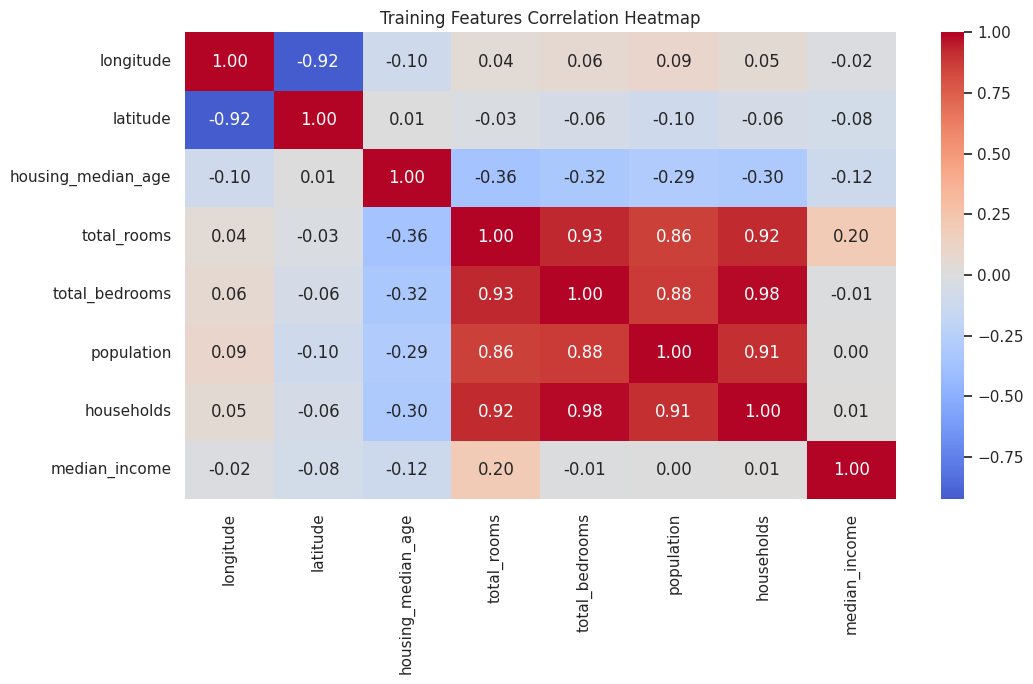

In [ ]:
# Also inspect feature-to-feature correlations
feature_corr = X_train.corr()

plt.figure(figsize=(11, 7))
sns.heatmap(feature_corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Training Features Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Example 1: one new record based on training-feature medians
new_house = pd.DataFrame(
    [X_train.median()],
    columns=features
)

print("New example:")
display(new_house)

new_prediction = multiple_model.predict(new_house)[0]
print(f"Predicted median house value: ${new_prediction:,.2f}")

New example:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-118.51,34.26,29.0,2129.0,437.0,1167.0,410.0,3.5458


Predicted median house value: $205,297.11


In [ ]:
# Example 2: user-defined illustrative values
custom_house = pd.DataFrame([{
    "longitude": -119.5,
    "latitude": 35.6,
    "housing_median_age": 25,
    "total_rooms": 2000,
    "total_bedrooms": 400,
    "population": 1000,
    "households": 350,
    "median_income": 4.0
}])

# Check whether each input lies within the training range
range_check = pd.DataFrame({
    "New value": custom_house.iloc[0],
    "Training minimum": X_train.min(),
    "Training maximum": X_train.max()
})
range_check["Within training range"] = (
    (range_check["New value"] >= range_check["Training minimum"]) &
    (range_check["New value"] <= range_check["Training maximum"])
)

display(range_check)

custom_prediction = multiple_model.predict(custom_house)[0]
print(f"Predicted median house value: ${custom_prediction:,.2f}")
print("Use caution if one or more features are outside the training range.")

,New value,Training minimum,Training maximum,Within training range
longitude,-119.5,-124.3500,-114.3100,True
latitude,35.6,32.5500,41.9500,True
housing_median_age,25.0,1.0000,52.0000,True
total_rooms,2000.0,2.0000,39320.0000,True
total_bedrooms,400.0,1.0000,6445.0000,True
population,1000.0,3.0000,35682.0000,True
households,350.0,1.0000,6082.0000,True
median_income,4.0,0.4999,15.0001,True


Predicted median house value: $204,703.66
Use caution if one or more features are outside the training range.


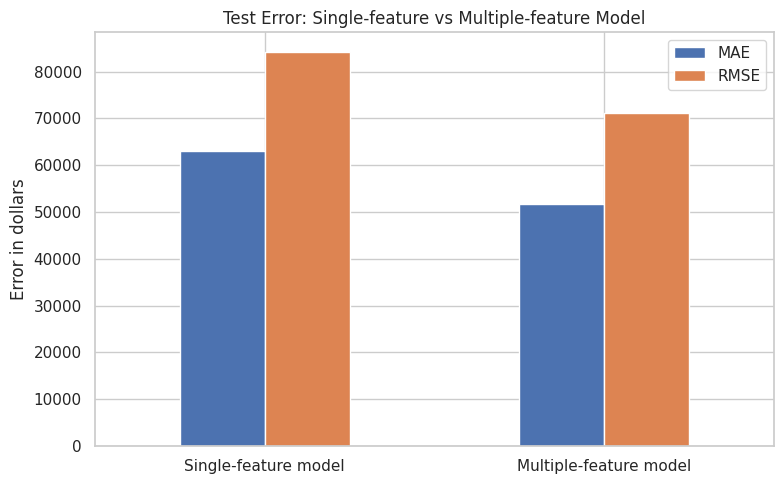

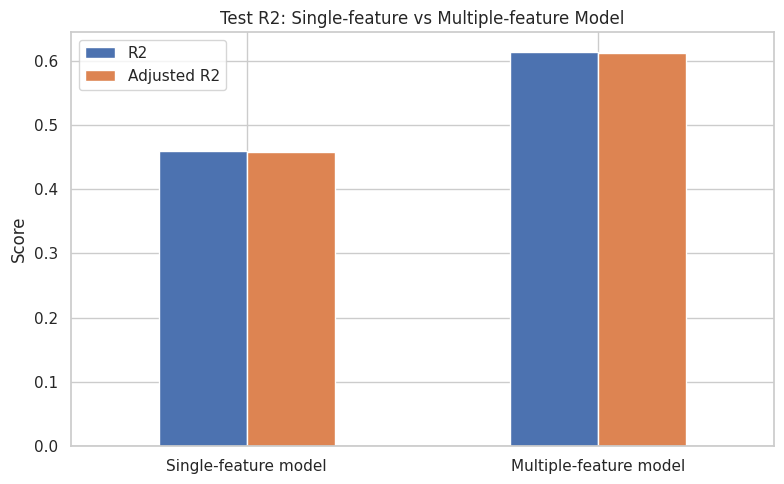

In [ ]:
# Compare error metrics in a chart (different scales, so interpret carefully)
results[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 5))
plt.title("Test Error: Single-feature vs Multiple-feature Model")
plt.ylabel("Error in dollars")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare R2 metrics separately
results[["R2", "Adjusted R2"]].plot(kind="bar", figsize=(8, 5))
plt.title("Test R2: Single-feature vs Multiple-feature Model")
plt.ylabel("Score")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()